# Lab 6: Convolutional neural networks (CNNs)

## 6.1. Basic architecture

* A convolutional neural network is composed of two types parts: a feature detection part and a classification part.

**Feature learning part**
* This part is mainly composed of:
    * Convolutional layers. 
    * Pooling layers.
* These layers intend to extract and detect features in the image.

**Classification part**
* The classification part is composed of:
    * A flatten layer as a result of the feature learning part.
    * A fully connected layer (FC) that outputs a vector of K dimensions where K is the number of classes that the network will be able to predict. This vector contains the probabilities for each class of any image being classified.
    * A final layer that uses a softmax function to provide the classification output.

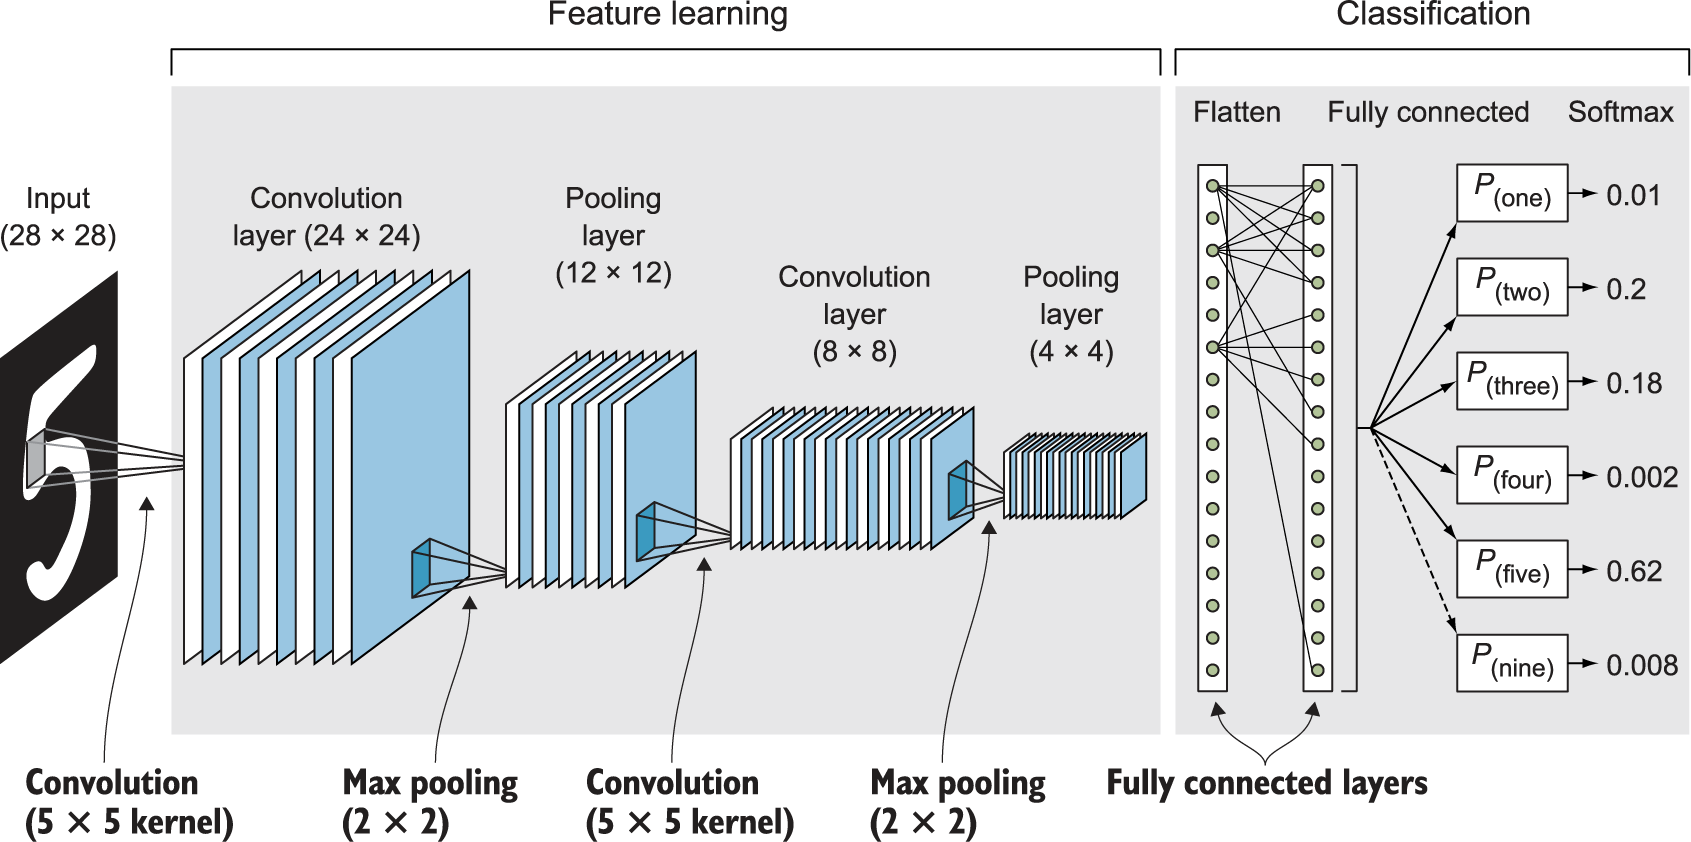

## 6.2. Convolutional layer

* A convolutional layer is composed by filters that include trainable parameters.
* Over the course of training, the filters will learn to detect certain features, like edges and textures, in the input image.

###  6.2.1. Basic functioning

* __Input feature map__
    - Our input data is a 2D matrix calle the *input feature map*. 
    - The feature map is initially our image data.
    - In subsequent layers it represents a mapping of where a certain kind of feature is found in the image, hence the name.
* __Filters__
    - A filter is composed at least by a _kernel_, which is simply a small matrix of weights, usually 3x3.
* __Applying the convolution operation__
    - The kernel “slides” over the 2D input data, performing an elementwise multiplication with the part of the input it is currently on, and then summing up the results into a single output pixel.
 
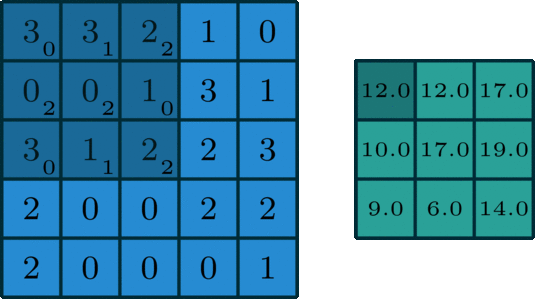

### 6.2.2 Padding

* The convolution operaton shrinks the feature map
* If you want to get an output feature map with the same spatial dimensions as the input, you can use **padding**.  
* Padding consists of adding an appropriate number of rows and columns on each side of the input feature map so as to make it possible to fit center convolution windows around every input tile. 
* For a 3 x 3 kernel over a 5 x 5 input, you add one column on the right, one column on the left, one row at the top, and one row at the bottom.

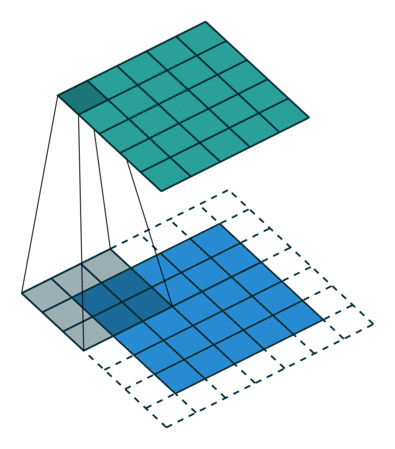

### 6.2.3 Strides

* Our description of convolution so far has assumed that the center tiles of the convolution windows are all contiguous. 
* But the distance between two successive windows is a parameter of the convolution, called its **stride** (*paso, zancada* in spanish)
* The previous convolutions have the stride to 1 (default stride or no stride).
* Using stride 2 means the width and height of the feature map are downsampled by a factor of 2 (in addition to any changes induced by border effects).
* Strided convolutions are rarely used in classification models, but they come in handy for some other types of models.

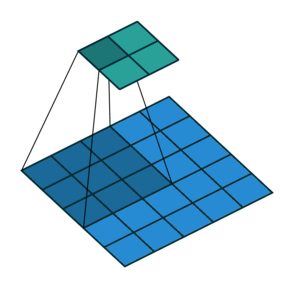

### 6.2.4. Multichannel images and multifilters

__Multichannel images and filters__
* In practicality, most input images have 3 channels for the three basic colors (red, blue and green).
* When applying a filter to a multichanneled image we will have a different kernel for each channel (i.e. the filters have depth dimension).
* So one filter is composed of several kernel (one for each of the depth layers in the feature map).

__Multifilters__
* In an image we apply not only one filter but several filters at the same time.
* The result of a convolution will be a new feature map, with dimensions probably reduced with respect to the original, and with a depth corresponding to the number of filters applied.

__Example__
* Input: a multichannel image.
* Applied two filters (with three kernels).
* Output: A new feature map, with dimensions reduced and with a depth that is equal to the number of filters applied.

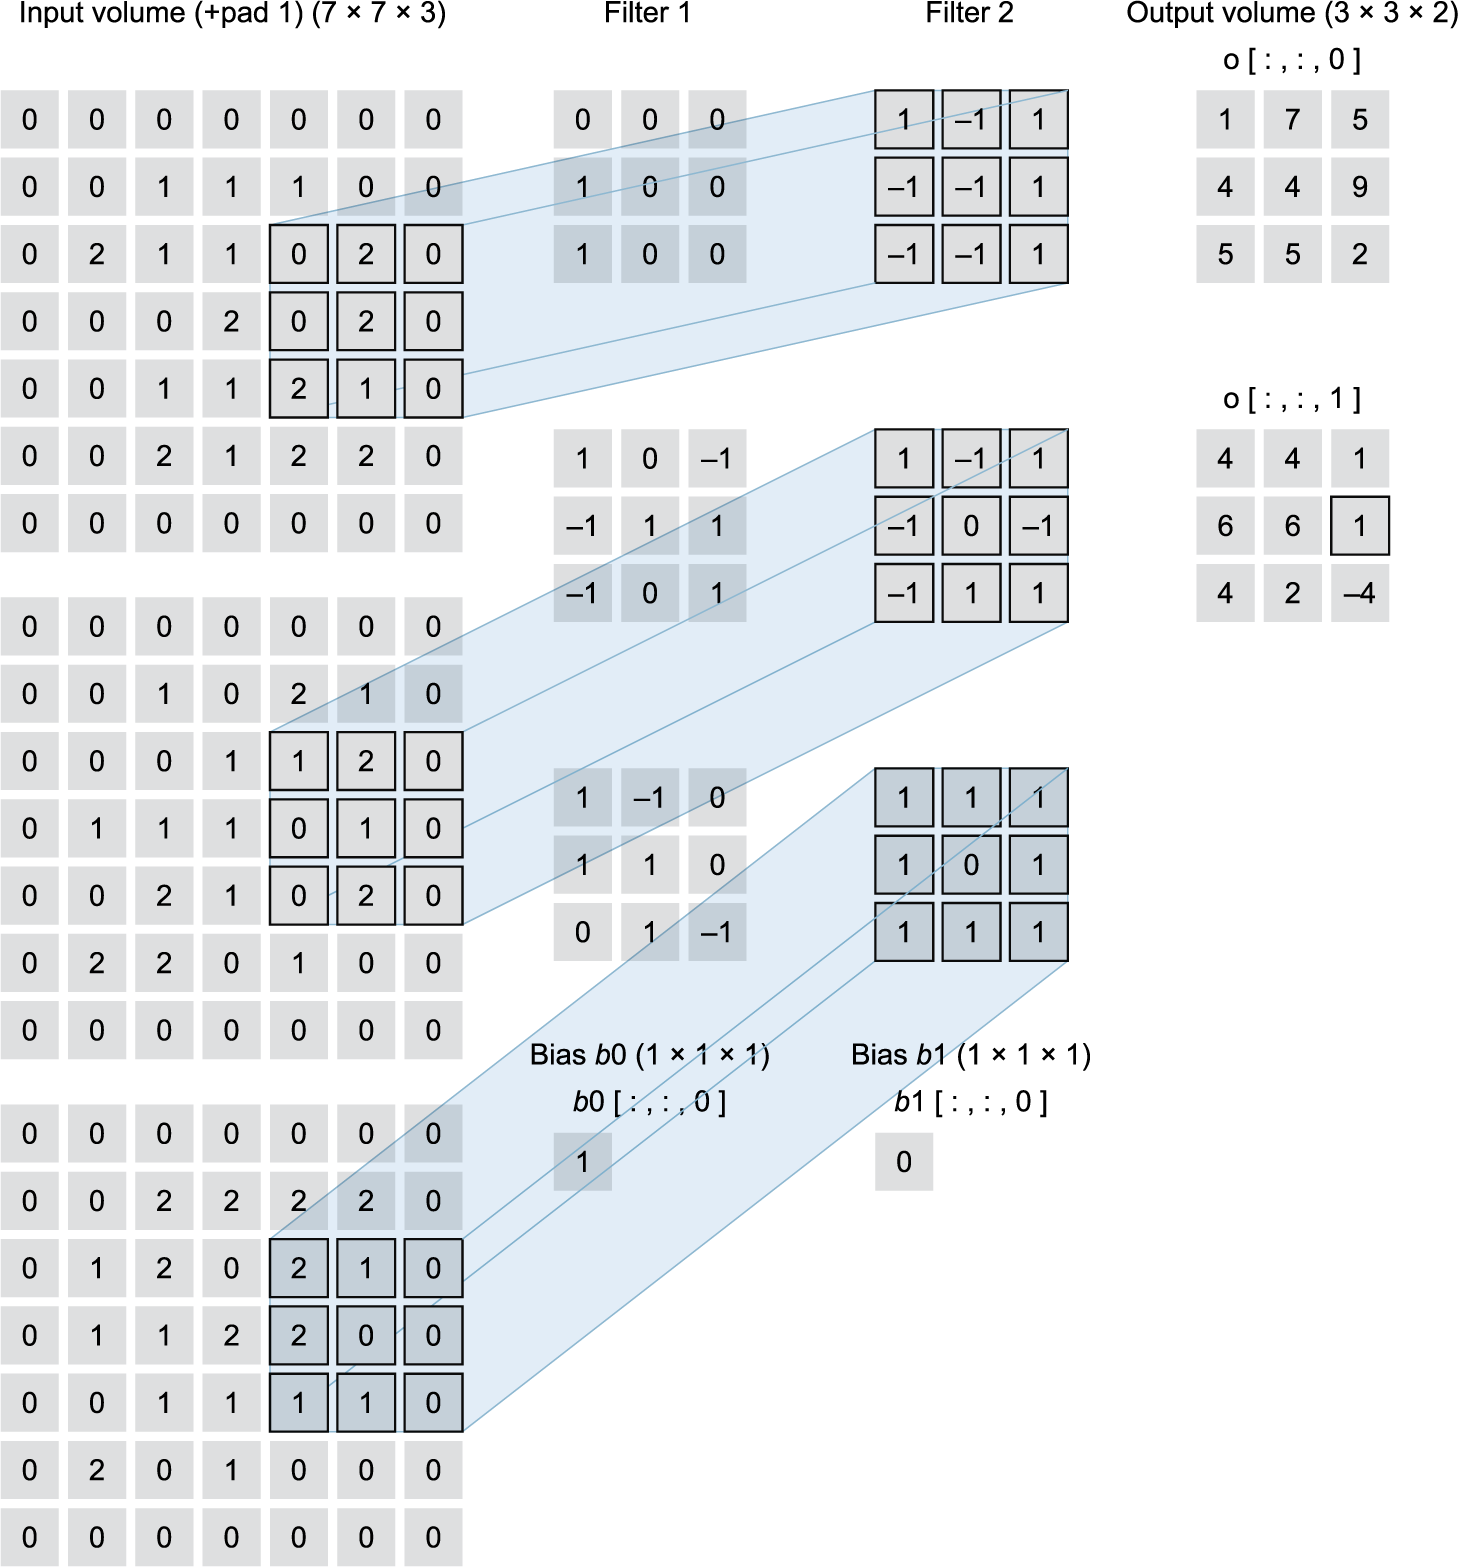

### 6.2.5. Convolutions in Keras

* __Convolutional classes__
    - A convolution layer is implemented in Keras using several classes: https://keras.io/api/layers/convolution_layers/
    - The most used is the two-dimensional convolution represented by the `Conv2D` class: https://keras.io/api/layers/convolution_layers/convolution2d/

* __`Conv2D` class main parameters__
  - __`filters`__: Integer, the dimensionality of the output space (i.e. the number of output filters in the convolution)
  - __`kernel_size`__: An integer or tuple/list of 2 integers, specifying the height and width of the 2D convolution window. Can be a single integer to specify the same value for all spatial dimensions.
  - __`padding`__: one of `"valid"` or `"same"` (case-insensitive). `"valid"` means no padding. `"same"` results in padding with zeros evenly to the left/right or up/down of the input. When `padding="same" and strides=1, the output has the same size as the input.
  - __`strides`__: An integer or tuple/list of 2 integers, specifying the strides of the convolution along the height and width. Can be a single integer to specify the same value for all spatial dimensions.
  - __`activation`__: Activation function to use. If you don't specify anything, no activation is applied


In [1]:
import keras
import numpy as np

x = np.random.rand(4, 10, 10, 128)
y = keras.layers.Conv2D(filters=32, 
                        kernel_size=3, 
                        padding="valid", 
                        strides=1,
                        activation='relu')(x)
print(y.shape)

(4, 8, 8, 32)


## 6.3. Pooling layer

### 6.3.1 Basic functioning

* Pooling operations reduce the size of feature maps by using some function to summarize subregions, such as taking the average or the maximum value (the most common one).
* Pooling works by sliding a window across the input and feeding the content of the window to a pooling function.
* __Comparison with convolutions__
    - Unlike convolutions, pooling layers do not include trainable parameters.
    - In pooling we do not specify the number of filters because the number of output filters is the same as the number of input filters (the pooling operation is applied independently to each filter).

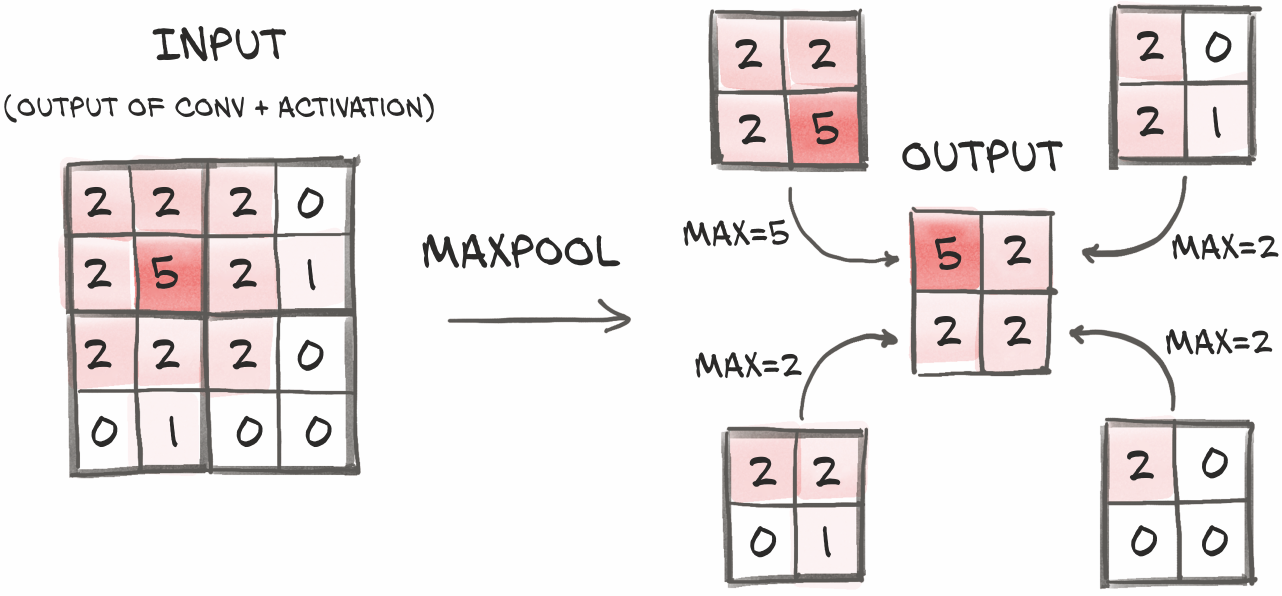


* **The reason to use downsampling by pooling is**:
  * To reduce the number of feature-map coefficients to process.
  * To induce spatial-filter hierarchies by making successive convolution layers look at increasingly large windows (in terms of the fraction of the original input they cover).
* Combined, convolutions and pooling can help the model to recognize larger structures in the image.

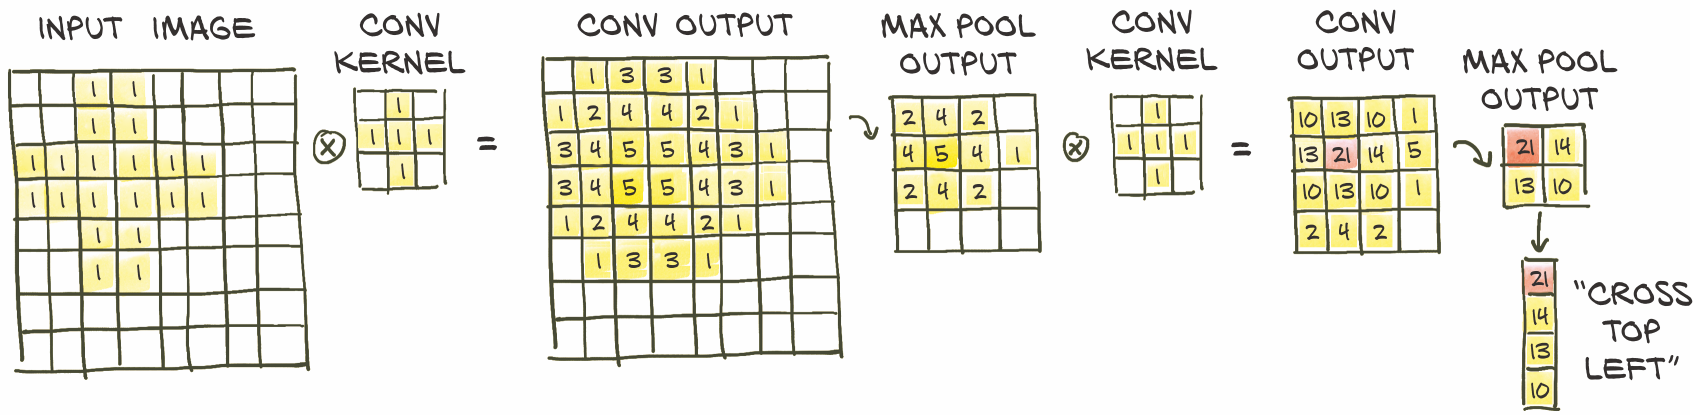

### 6.3.2. Pooling layers in Keras

* __Pooling classes__
    - A pooling layer is implemented in Keras using several classes: https://keras.io/api/layers/pooling_layers/
    - The most used is the two-dimensional max pooling layer represented by the `MaxPooling2D` class: https://keras.io/api/layers/pooling_layers/max_pooling2d/
*  __`MaxPooling2D` class main parameters__
    - __`pool_size`__: Integer or tuple of 2 integers, window size over which to take the maximum. (2, 2) will take the max value over a 2x2 pooling window. If only one integer is specified, the same window length will be used for both dimensions.
    - __`padding`__: One of `"valid"` or `"same"` (case-insensitive). `"valid"` means no padding. `"same"` results in padding evenly to the left/right or up/down of the input such that output has the same height/width dimension as the input.
    - __`strides`__: Integer, tuple of 2 integers, or None. Strides values. Specifies how far the pooling window moves for each pooling step. If `None`, it will default to `pool_size`.

In [2]:
# strides=(1, 1) and padding="valid"
x = np.array([[1., 2., 3.],
              [4., 5., 6.],
              [7., 8., 9.]])
x = np.reshape(x, [1, 3, 3, 1])
max_pool_2d = keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=(1, 1), 
    padding="valid")
max_pool_2d(x)

<tf.Tensor: shape=(1, 2, 2, 1), dtype=float32, numpy=
array([[[[5.],
         [6.]],

        [[8.],
         [9.]]]], dtype=float32)>

In [3]:
# strides=(2, 2) and padding="valid"
x = np.array([[1.,  2.,  3.,  4.],
              [5.,  6.,  7.,  8.],
              [9., 10., 11., 12.]])
x = np.reshape(x, [1, 3, 4, 1])
max_pool_2d = keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=(2, 2), 
    padding="valid")
max_pool_2d(x)

<tf.Tensor: shape=(1, 1, 2, 1), dtype=float32, numpy=
array([[[[6.],
         [8.]]]], dtype=float32)>

In [4]:
# stride=(1, 1) and padding="same"
x = np.array([[1., 2., 3.],
              [4., 5., 6.],
              [7., 8., 9.]])
x = np.reshape(x, [1, 3, 3, 1])
max_pool_2d = keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=(1, 1), 
    padding="same")
max_pool_2d(x)

<tf.Tensor: shape=(1, 3, 3, 1), dtype=float32, numpy=
array([[[[5.],
         [6.],
         [6.]],

        [[8.],
         [9.],
         [9.]],

        [[8.],
         [9.],
         [9.]]]], dtype=float32)>

## 6.4. Our first CNN example (MNIST)

* First, let’s take a look at a simple convnet example that classifies MNIST digits.
* We’ll build the model using the Keras Functional API.

### 6.4.1. Instantiating a small CNN

* __Input__
  - A CNN takes as input tensors of shape `(image_height, image_width, image_channels)`, not including the batch dimension. 
  - In this case, we’ll configure the CNN to process inputs of size `(28, 28, 1)`, which is the format of MNIST images.

* __Feature detection layers__
  - Our feature detection layers is a stack of `Conv2D` and `MaxPooling2D` layers.
  - We can see that the output of every `Conv2D` and `MaxPooling2D` layer is a rank-3 tensor of shape (height, width, channels). 
  - The width and height dimensions tend to shrink as you go deeper in the model. 
  - The number of channels is controlled by the first argument (`filters`) passed to the `Conv2D` layers (32, 64, or 128).
  - After the last `Conv2D` layer, we end up with an output of shape (3, 3, 128)—a 3 × 3 feature map of 128 channels. 

* __Feature map evolution__

* The __size of the feature map__ decreases through the layers because we use pooling or strides (or we don`t use the "same" padding).
    - The reason of downsampling the feature map is useful to reduce the number of  coefficients to process and to look at increasingly large windows of the original image.
* The __depth of the feature__ map progressively increases in the model, we have more filters in the final layers than in the initial layers.
    - Every layer of filters is there to capture patterns.
    - The first layer of filters captures basic patterns like edges, corners, dots etc.
    - Subsequent layers combine those patterns to make bigger patterns (like combining edges to make squares, circles, etc.).
    - Now as we move forward in the layers, the patterns get more complex; hence there are larger combinations of patterns to capture, and we need more filters to do that.
* At the end of the feature detection layers we will end up with a long tube of small shaped images that contain all the features in the original image.

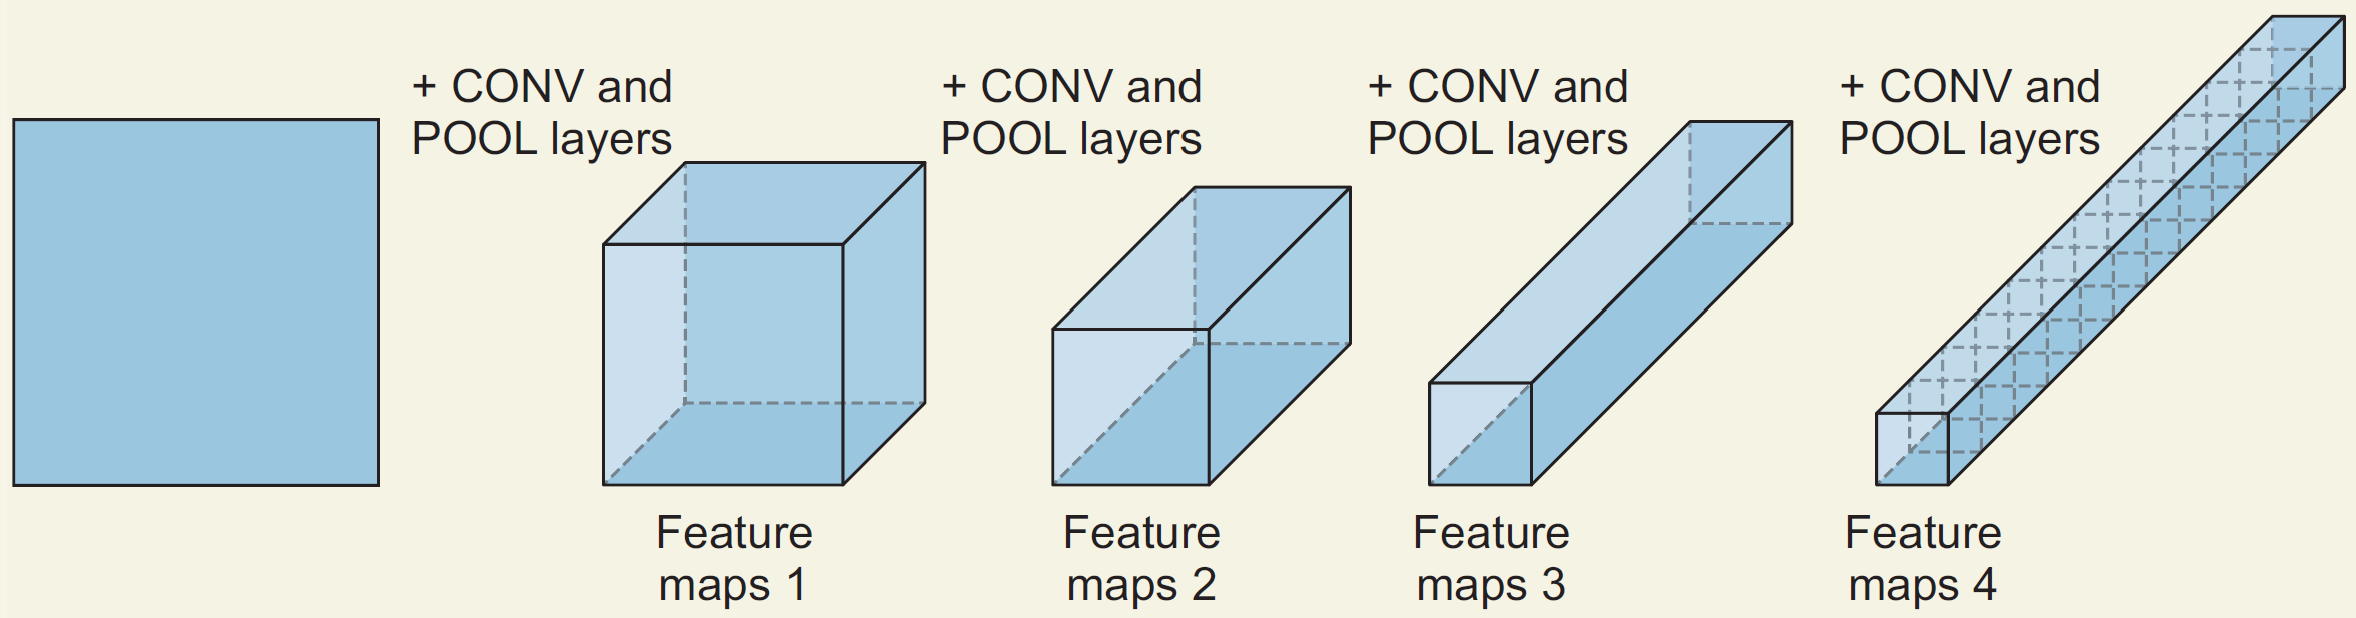

* __Classification layers__
  - The next step is to feed this output into a densely connected classifier like those we’re already familiar with: a stack of `Dense` layers. 
  - These classifiers process vectors, which are 1D, whereas the current output is a rank-3 tensor. To bridge the gap, we flatten the 3D outputs to 1D with a `Flatten` layer before adding the `Dense` layers.
  - Finally, we do 10-way classification, so our last layer has 10 outputs and a `softmax` activation.

In [5]:
import keras
from keras import layers
inputs = keras.Input(shape=(28, 28, 1))

# Feature learning part
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(inputs)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)

# Classification part
x = layers.Flatten()(x)
outputs = layers.Dense(10, activation="softmax")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

### 6.4.2. Displaying the model's summary

* **Using the summary function**

In [6]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,202 (407.04 KB)

 Trainable params: 104,202 (407.04 KB)

 Non-trainable params: 0 (0.00 B)

* **Using the plot_model functionality**

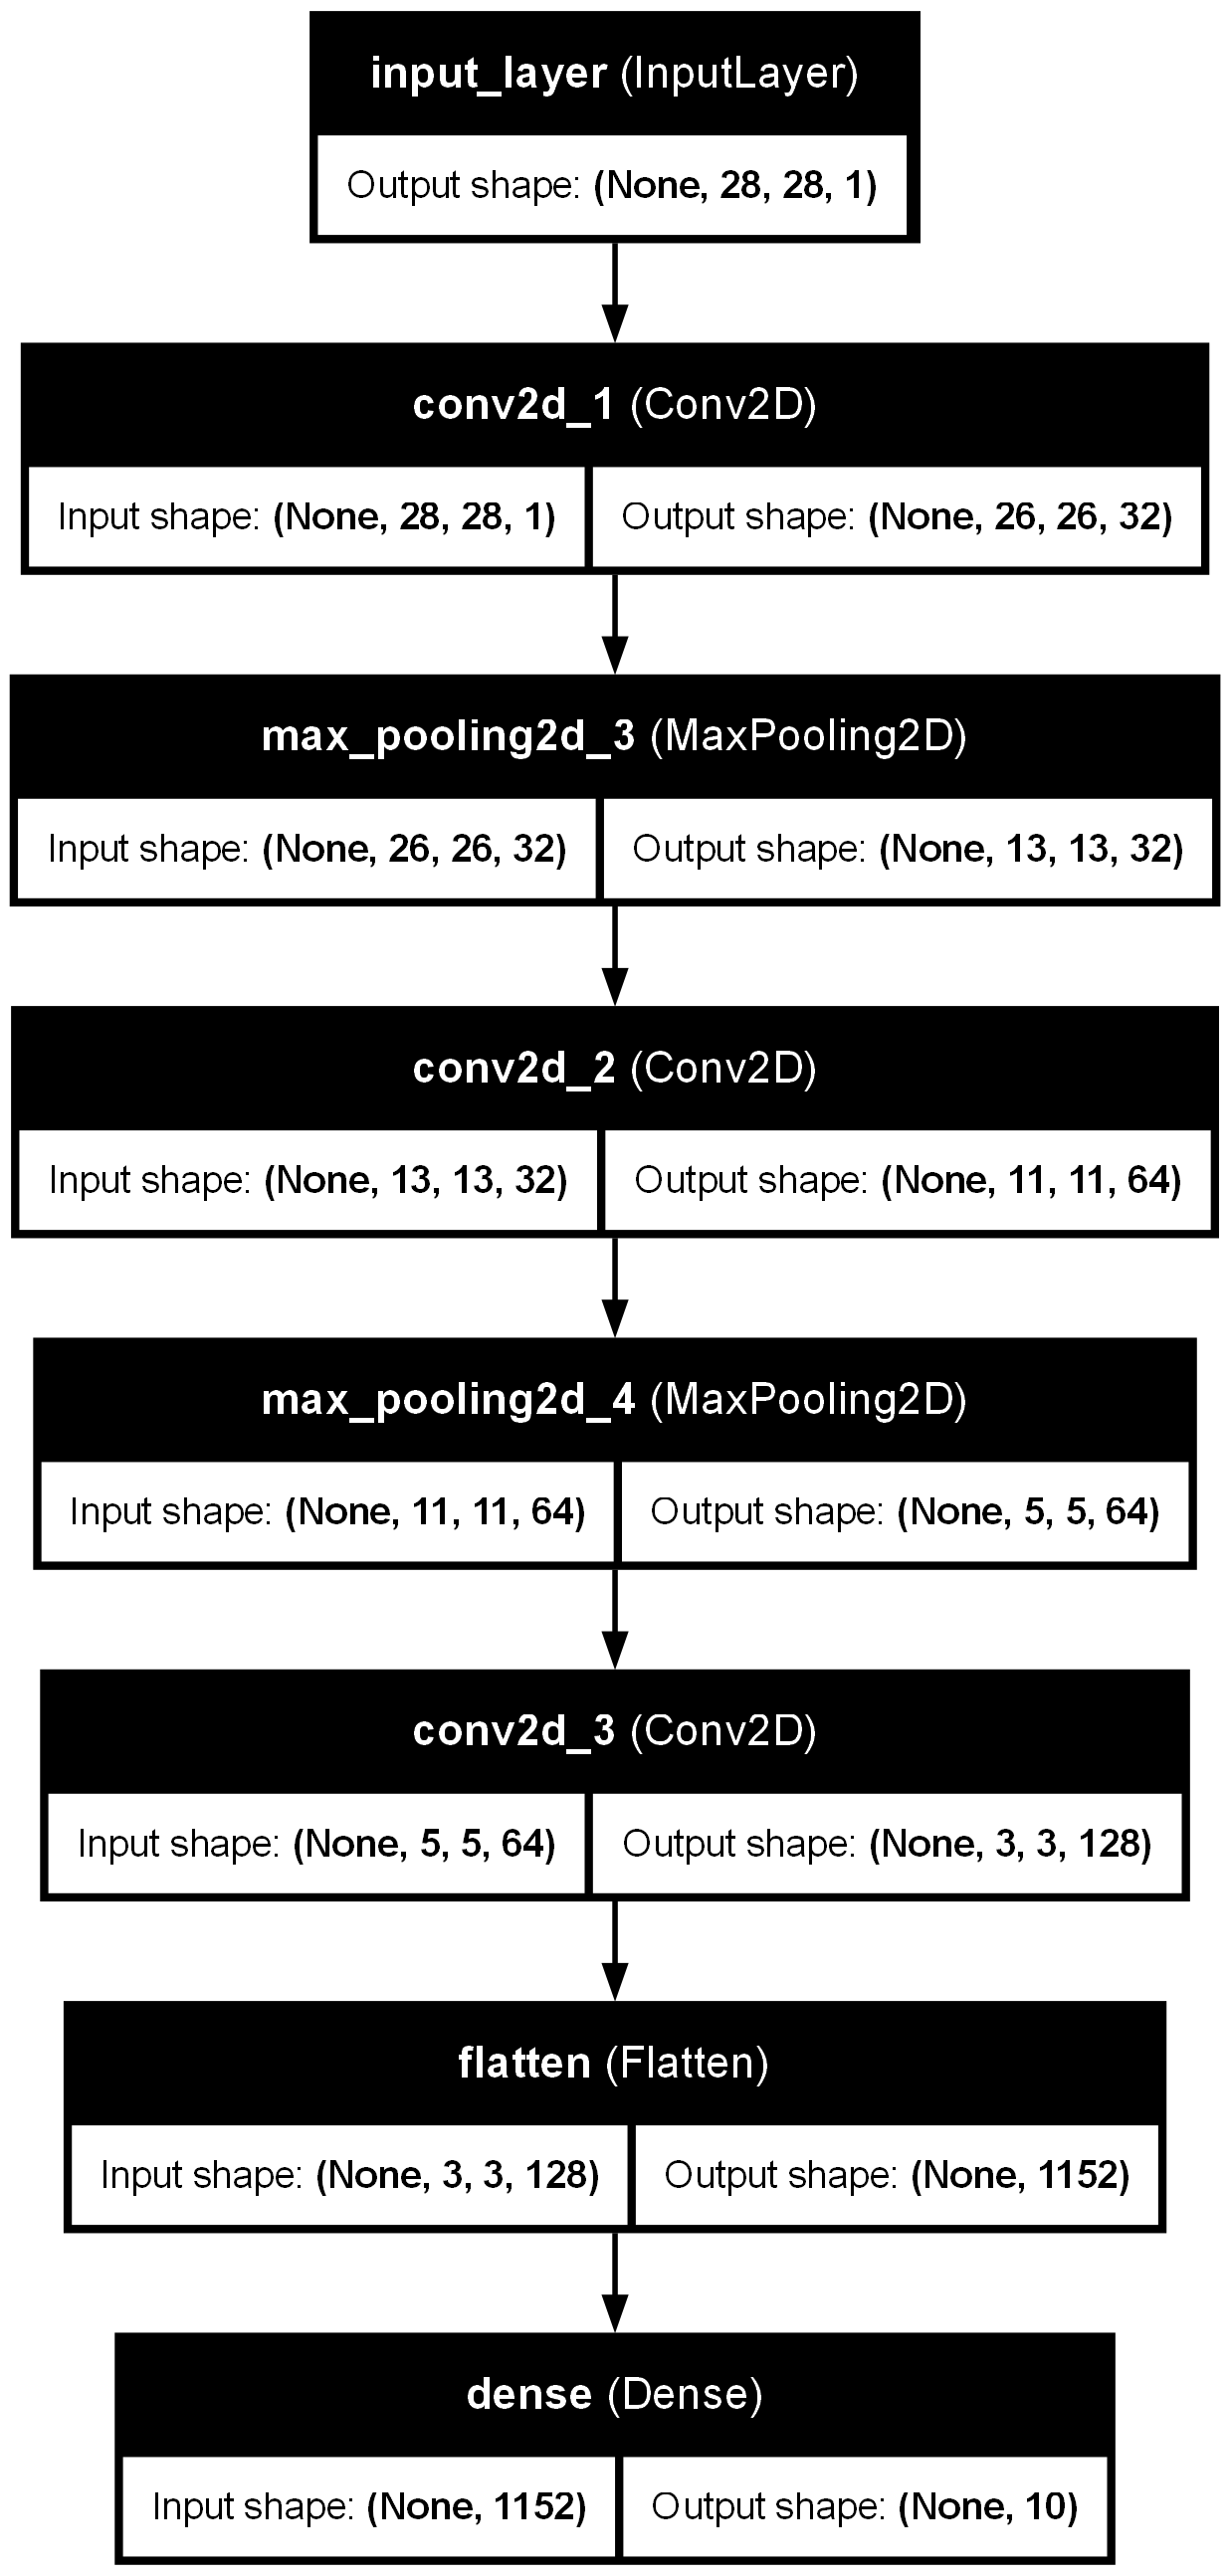

In [7]:
# Using the plot_model functionality
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True)

* __Using a custom graphical representation__

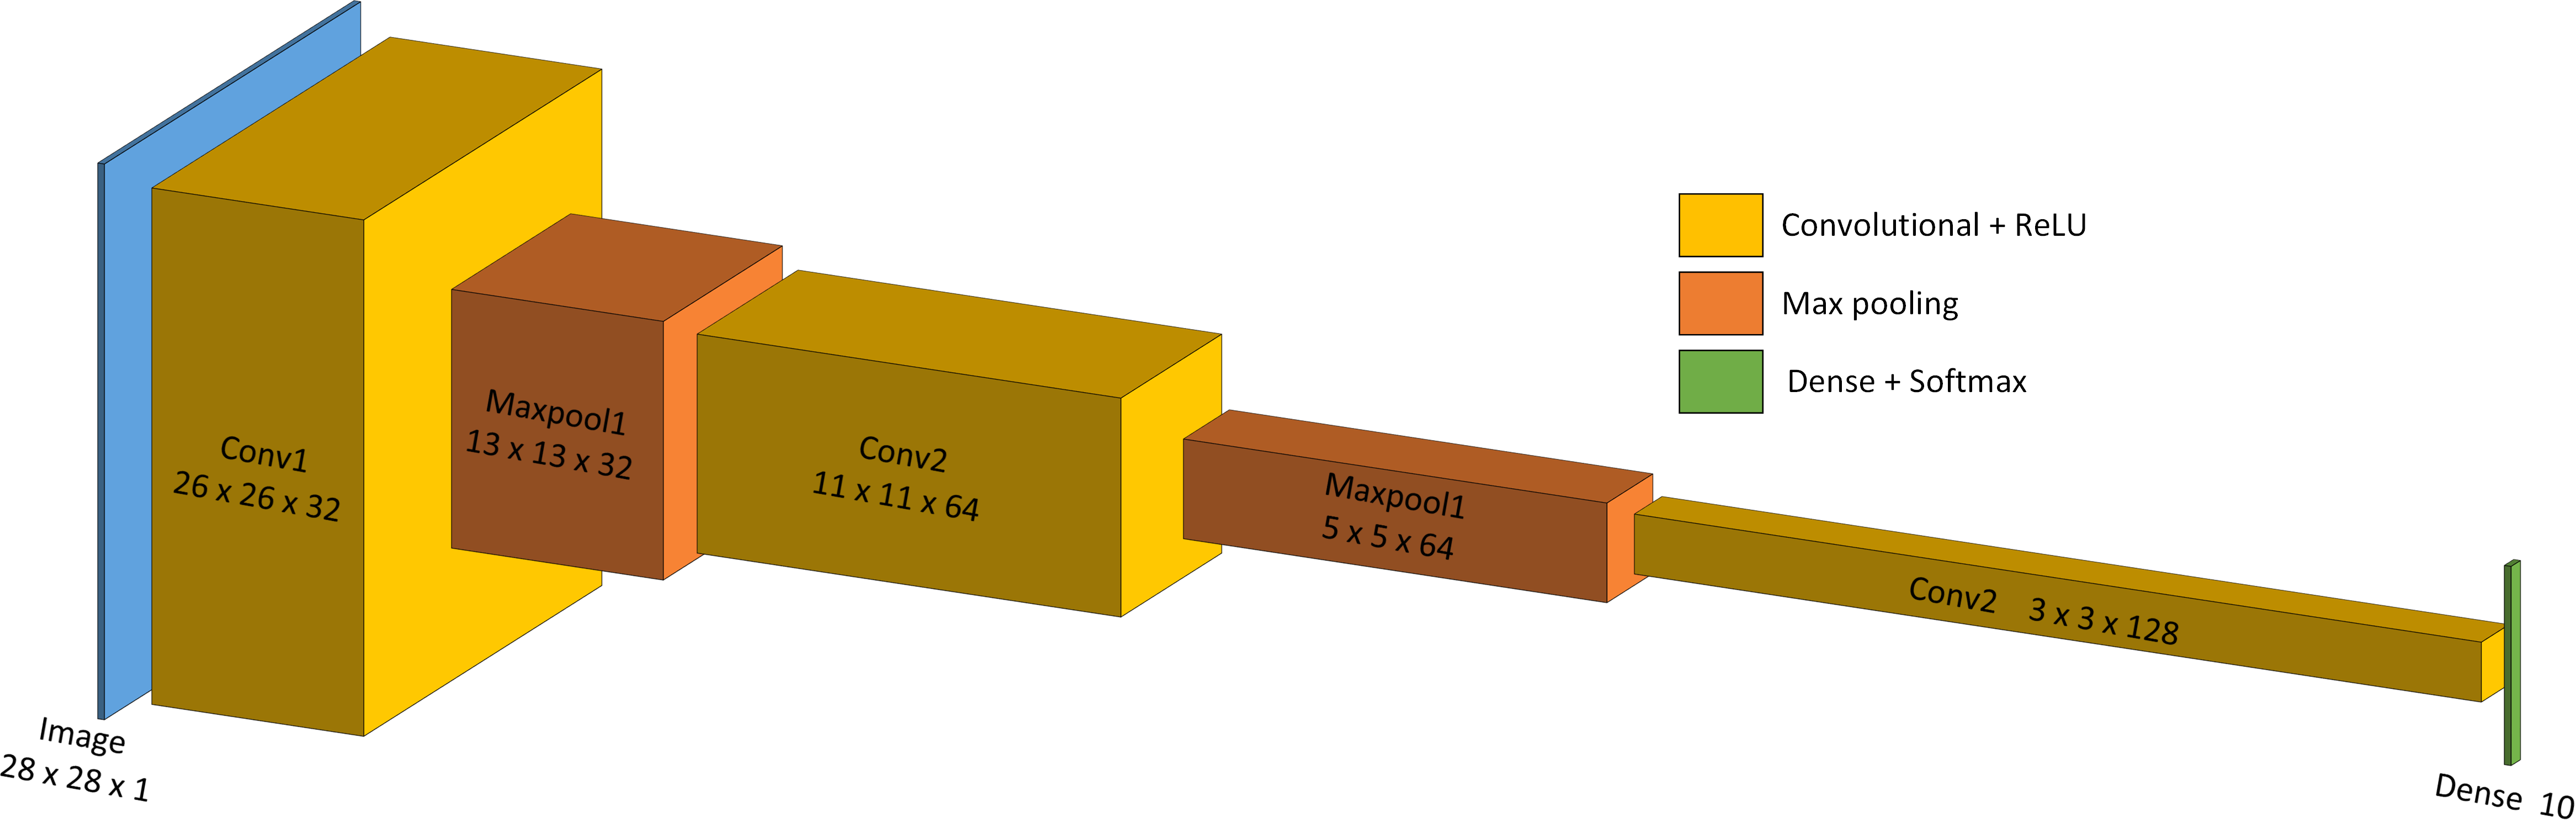

* __Using the `visualkeras` library__

    - The functional model is only supporte for linear models where each layer has no more than one in or output.
    - Non-linear models will be shown in sequential order.
    - https://github.com/paulgavrikov/visualkeras

C:\Users\Usuario\anaconda3\envs\AP-311\Lib\site-packages\visualkeras\layered.py:86: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


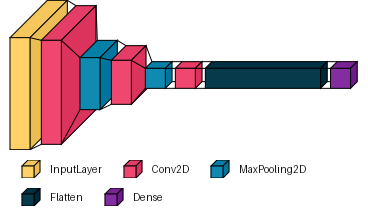

In [8]:
import visualkeras
# Result with legend
visualkeras.layered_view(model, legend=True)

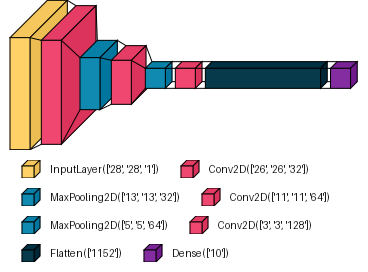

In [9]:
# Result with dimensions in the layer
visualkeras.layered_view(model, legend=True, show_dimension=True)

### 6.4.3. Training the CNN on MNIST images

* Let’s train the convnet on the MNIST digits. 
* Because we’re doing 10-way classification with a softmax output, we’ll use the categorical crossentropy loss
* Because our labels are integers, we’ll use the sparse version, `sparse_categorical_crossentropy`.

In [10]:
from keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 28, 28, 1))
train_images = train_images.astype("float32") / 255
test_images = test_images.reshape((10000, 28, 28, 1))
test_images = test_images.astype("float32") / 255
model.compile(optimizer="rmsprop",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])
model.fit(train_images, train_labels, epochs=5, batch_size=64)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9504 - loss: 0.1603
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9855 - loss: 0.0454
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9902 - loss: 0.0315
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9931 - loss: 0.0238
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9944 - loss: 0.0182


### 6.4.4. Evaluating the CNN

In [11]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"Test accuracy: {test_acc:.3f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9905 - loss: 0.0334
Test accuracy: 0.990


* Whereas the densely connected model had a test accuracy of 97.8%, the basic convnet has a test accuracy of 99.1%
<!-- * We decreased the error rate by about 60% (relative). -->

## 6.5. CNN example on a small dataset (dogs vs. cats)

* We’ll focus on classifying images as dogs or cats in a dataset containing 5,000 pictures (2,500 cats, 2,500 dogs). 
* We’ll use 2,000 pictures for training, 1,000 for validation, and 2,000 for testing.
* We’ll start by training a small CNN without any regularization, to set a baseline for what can be achieved.
* When the overfitting issues appear, we will use regularization to avoid it.

### 6.5.1. Dataset

#### Original dataset

* The Dogs vs. Cats dataset isn’t packaged with Keras. 
* It was made available by Kaggle as part of a computer vision competition.
* You can download it from: https://www.kaggle.com/c/dogs-vs-cats/data
* This dataset contains 25,000 images of dogs and cats (12,500 from each class) and is 543 MB (compressed).
* Photos have different sizes, colors, backgrounds, etc.
  
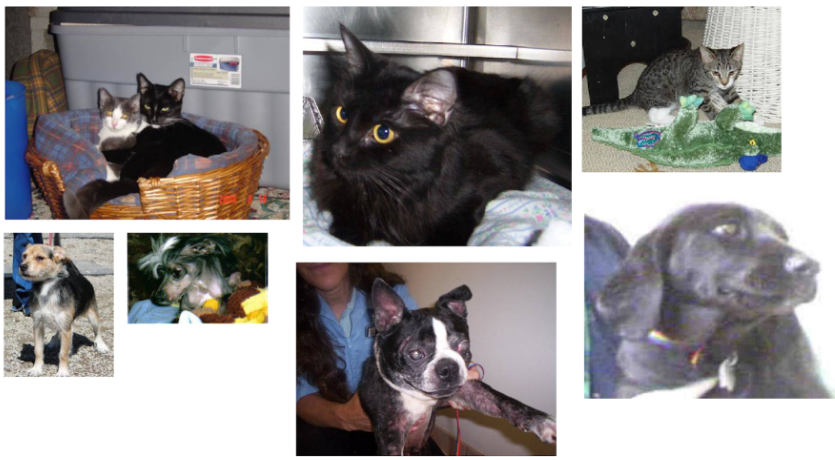

#### Reduced dataset

* We will work with a small subset of this dataset for these reasons:
    - It is easier to work with and faster to train a network with a smaller dataset.
    - It allows us to demonstrate that a DL model can learn from relatively small samples.
    - When the overfitting issues appear, we will use regularization to avoid it.
    - Demonstrate that, because CNNs learn local, translation-invariant features, they’re highly data-efficient on perceptual problems.

#### Code for reducing the dataset

* The following code takes the original data set from the `original_dir` and creates a reduced version on `new_base_dir`.
* The smaller version will have 2,000 pictures for training, 1,000 for validation, and 2,000 for testing extracted from the original train set.
* The smaller dataset is equally divided in dogs and cats for the training (1,000 samples of each class), validation (500 samples of each class) and test (1,000 samples of each class) sets.
* __You have available already the reduced version of the dataset, therefore you can skip running this conversion code.__

In [12]:
# code for converting original "cats vs. dogs" dataset in the smaller version.
import os, shutil, pathlib
import keras
  
# Use your specific paths here
original_dir = pathlib.Path("C:/datasets/dogs-vs-cats_original/train")
new_base_dir = pathlib.Path("C:/datasets/dogs-vs-cats_small")

In [13]:
def make_subset(subset_name, start_index, end_index):
    for category in ("cat", "dog"):
        dir = new_base_dir / subset_name / category
        os.makedirs(dir)
        fnames = [f"{category}.{i}.jpg" for i in range(start_index, end_index)]
        for fname in fnames:
            shutil.copyfile(src=original_dir / fname, dst=dir / fname)

            
make_subset("train", start_index=0, end_index=1000)
make_subset("validation", start_index=1000, end_index=1500)
make_subset("test", start_index=1500, end_index=2500)

* After running the previous code we will obtain the following directory structure:

```
dogs_vs_cats_small/
...train/
......cat/
......dog/
...validation/
......cat/
......dog/
...test/
......cat/
......dog/
```

* __NOTE: We have uploaded a ZIP file (108MB) with this small dataset to the virtual campus.__
* So there is now need to extract the dataset by yourself. Simply __update the `new_base_dir` path to the local path in which you have downloaded the small dataset__.

### 6.5.2. Preprocessing

#### Data preprocessing

* Data should be formatted into appropriately preprocessed floating-point tensors before being fed into the model. 
* The tasks to be done are:
    * Read the picture files.
    * Decode the JPEG content to RGB grids of pixels.
    * Convert these into floating-point tensors.
    * Resize them to a shared size (they do not have the same size) and also reduce the size to a more manageable one (180 × 180).
    * Pack them into batches (we’ll use batches of 32 images).    

#### Keras `image_dataset_from_directory()` function

* Keras has a utility function that does all the previous steps for us: `image_dataset_from_directory(directory)`
* See the documentation here: https://keras.io/api/preprocessing/image/
* __main arguments__:
    - `directory`: Directory where the data is located. If labels is `"inferred"`, it should contain subdirectories, each containing images for a class. 
    - `labels`: Either `"inferred"` (labels are generated from the directory structure), `None` (no labels), or a list/tuple of integer labels of the same size as the number of image files found in the directory.
    - `image_size`: Size to resize images to after they are read from disk, specified as `(height, width)`. Defaults to `(256, 256)`.
    - `batch_size`: Size of the batches of data. Defaults to `32`. If None, the data will not be batched (the dataset will yield individual samples).
    - `validation_split`: Optional float between 0 and 1, fraction of data to reserve for validation.
    - `interpolation`: The interpolation method used when resizing images. Defaults to `bilinear`.
    - `crop_to_aspect_ratio`: If `True`, resize the images without aspect ratio distortion by cropping the images. By default (`crop_to_aspect_ratio=False`), aspect ratio may not be preserved.
    - `pad_to_aspect_ratio`: If `True`, resize the images without aspect ratio distortion by using padding. By default (`pad_to_aspect_ratio=False`), aspect ratio may not be preserved.

In [14]:
# Using image_dataset_from_directory to read images

from keras.utils import image_dataset_from_directory
  
train_dataset = image_dataset_from_directory(
    new_base_dir / "train",
    image_size=(180, 180),
    batch_size=32)
validation_dataset = image_dataset_from_directory(
    new_base_dir / "validation",
    image_size=(180, 180),
    batch_size=32)
test_dataset = image_dataset_from_directory(
    new_base_dir / "test",
    image_size=(180, 180),
    batch_size=32)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.


### 6.5.3. Building and training the CNN

#### Building the model

* The CNN will be a stack of alternated `Conv2D` (with relu activation) and `MaxPooling2D` layers, as in the MNIST example.
* Since the problem is more complex we'll make our model larger: with two more `Conv2D` and `MaxPooling2D` stages. 
* This allow us to augment the capacity of the model and to further reduce the size of the feature maps so they aren’t overly large when we reach the `Flatten` layer. 

In [15]:
from keras import layers
  
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1./255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

In [16]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        12,545 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 991,041 (3.78 MB)

 Trainable params: 991,041 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

<img src="images/CNNs/convnet_cats_dogs.png" width=945 />

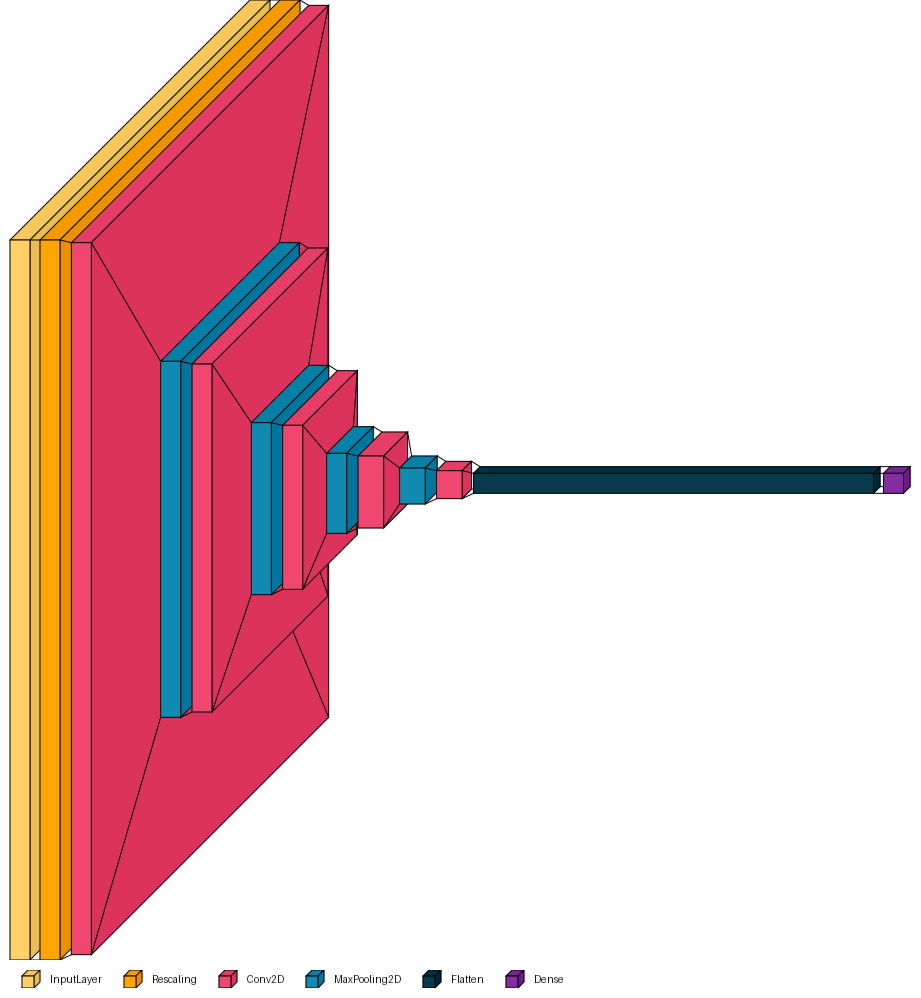

In [17]:
from collections import defaultdict
# visualkeras apply colors in order following a specified color wheel.
# Default color wheel of visual keras
# ["#ffd166", "#ef476f", "#118ab2", "#073b4c", "#842da1", "#ffbad4", "#fe9775", "#83d483", "#06d6a0", "#0cb0a9"]
# We can change the colors to mantain consistency

color_map = defaultdict(dict)
color_map[layers.Input]['fill'] = '#ffd166'
color_map[layers.Rescaling]['fill'] = 'orange'
color_map[layers.Conv2D]['fill'] = '#ef476f'
color_map[layers.MaxPooling2D]['fill'] = '#118ab2'
color_map[layers.Flatten]['fill'] = '#073b4c'
color_map[layers.Dense]['fill'] = '#842da1'

visualkeras.layered_view(model, legend=True, color_map=color_map)

In [18]:
# compilation step
model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

#### Training the model with the `ModelCheckpoit` callback.

* We use a `ModelCheckpoint` callback to monitor de validation loss and tell the callback to only save a new file (overwriting any previous one) when the current value of the `val_loss` metric is lower than at any previous time during training.
* This guarantees that your saved file will always contain the state of the model corresponding to its best-performing training epoch, in terms of its performance on the validation data.
* As a result, we won’t have to retrain a new model for a lower number of epochs if we start overfitting: we can just reload our saved file.
* Main parameters:
    - `filepath`: `string` or `PathLike`, path to save the model file.
    - `save_best_only`: if `save_best_only=True`, it only saves when the model is considered the "best" and the latest best model according to the quantity monitored will not be overwritten. 
    - `monitor`: The metric name to monitor.
* See: https://keras.io/api/callbacks/model_checkpoint/

In [19]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="models/U3-CNNs/dogs-vs-cats_initial.keras",
        save_best_only=True,
        monitor="val_loss")
]
history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 225ms/step - accuracy: 0.5165 - loss: 0.6923 - val_accuracy: 0.5790 - val_loss: 0.6803
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 219ms/step - accuracy: 0.5845 - loss: 0.6794 - val_accuracy: 0.5730 - val_loss: 0.6788
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 214ms/step - accuracy: 0.5860 - loss: 0.6761 - val_accuracy: 0.5910 - val_loss: 0.6703
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 214ms/step - accuracy: 0.6410 - loss: 0.6410 - val_accuracy: 0.6620 - val_loss: 0.6208
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 213ms/step - accuracy: 0.6545 - loss: 0.6271 - val_accuracy: 0.6480 - val_loss: 0.6292
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 216ms/step - accuracy: 0.6935 - loss: 0.5824 - val_accuracy: 0.6750 - val_loss: 0.5989
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 214ms/step - accuracy: 0.7015 - loss: 0.5728 - val_accuracy: 0.6970 - val_loss: 0.5774
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 211ms/step - accuracy: 0.7730 - loss: 0.4860 - val_accu

In [20]:
import matplotlib.pyplot as plt

def plot(history):
    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs = range(1, len(accuracy) + 1)

    plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
    plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
    plt.title("Training and validation accuracy")
    plt.legend()
    plt.figure()

    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r--o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.show()

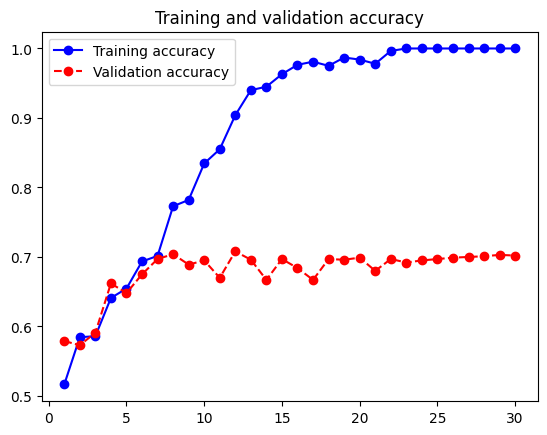

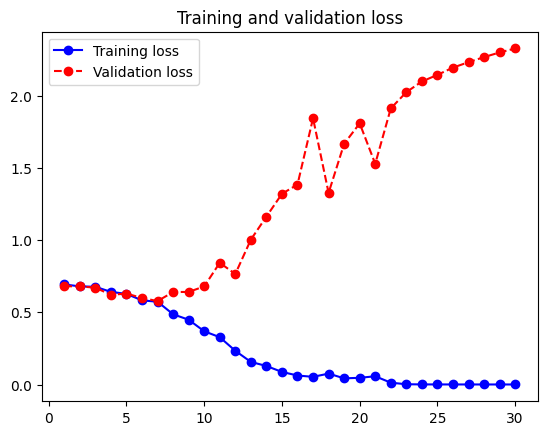

In [21]:
plot(history)

* These plots are characteristic of overfitting. 
* The training accuracy increases linearly over time, until it reaches nearly 100%, whereas the validation accuracy peaks at 75%. 
* The validation loss reaches its minimum after less than ten epochs and then starts to increase, whereas the training loss keeps decreasing linearly as training proceeds.

In [22]:
test_model = keras.models.load_model("models/U3-CNNs/dogs-vs-cats_initial.keras")
test_loss, test_acc = test_model.evaluate(test_dataset) 
print(f"Test accuracy: {test_acc:.3f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.6965 - loss: 0.6146
Test accuracy: 0.697


* We’ll reload the model from its saved file to evaluate it as it was before it started overfitting.
* The test accuracy is more or less 70%

### 6.5.4. Regularization using data augmentation and dropout

#### Data augmentation layers

* Overfitting is caused by having too few samples to learn from, rendering you unable to train a model that can generalize to new data.
* One easy technique to obtain new data when working with images is **data augmentation**.
* Data augmentation takes the approach of generating more training data from existing training samples by augmenting the samples via a number of random transformations that yield believable-looking images.
* This helps expose the model to more aspects of the data so it can generalize better.
* In Keras, this can be done by adding a number of data augmentation layers at the start of your model (see https://keras.io/api/layers/preprocessing_layers/image_augmentation/):
    - `RandomFlip` is a layer that randomly flip each image horizontally and vertically.
    - `RandomRotation` randomly rotates images. The `0.1` parameters indicates varying the value by a margin of [–10%, +10%]
    - `RandomRotation` randomly zooms images. The `0.2` parameters indicates varying the value by a margin of [–20%, +20%]   
* The goal is that, at training time, your model will never see the exact same picture twice. 

In [23]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2),
    ]
)

* Some examples of augmented images

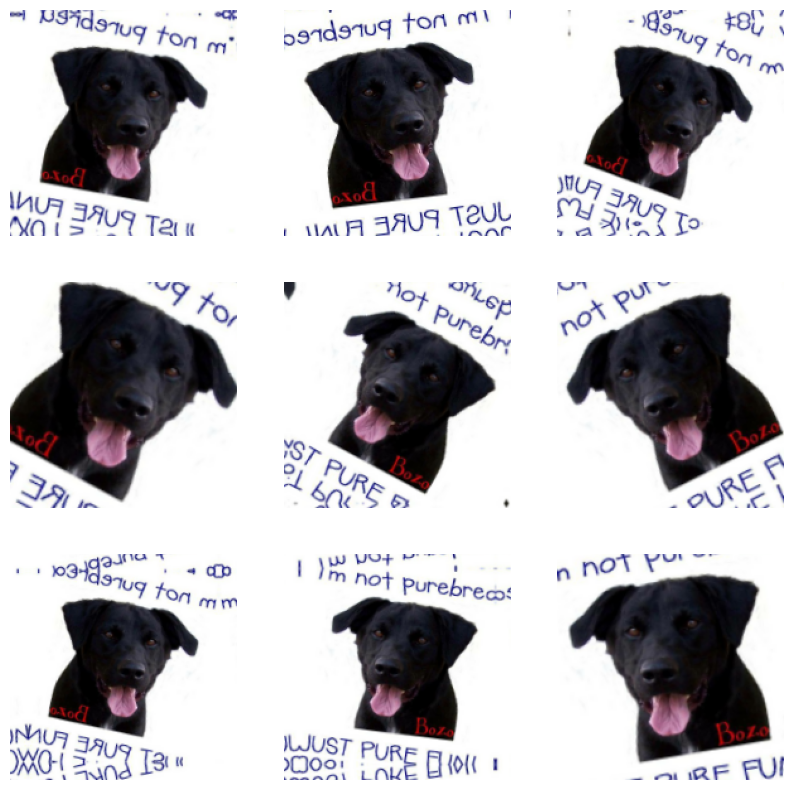

In [24]:
plt.figure(figsize=(10, 10)) 
for images, _ in train_dataset.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(augmented_images[0].numpy().astype("uint8"))
        plt.axis("off")

* We also add a __dropout__ layer after the *flatten* to favor generalization.

In [25]:
# Defining a new CNN that includes image augmentation and dropout

inputs = keras.Input(shape=(180, 180, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1./255)(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs=inputs, outputs=outputs)
  
model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

In [26]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="models/U3-CNNs/dogs-vs-cats_augmentation.keras",
        save_best_only=True,
        monitor="val_loss")
]
history = model.fit(
    train_dataset,
    epochs=60,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 227ms/step - accuracy: 0.5290 - loss: 0.6919 - val_accuracy: 0.5940 - val_loss: 0.6752
Epoch 2/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 232ms/step - accuracy: 0.5380 - loss: 0.6879 - val_accuracy: 0.5020 - val_loss: 0.6957
Epoch 3/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 232ms/step - accuracy: 0.5205 - loss: 0.6920 - val_accuracy: 0.5370 - val_loss: 0.6860
Epoch 4/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 229ms/step - accuracy: 0.5235 - loss: 0.6896 - val_accuracy: 0.5450 - val_loss: 0.6807
Epoch 5/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 227ms/step - accuracy: 0.5195 - loss: 0.7023 - val_accuracy: 0.4990 - val_loss: 0.6944
Epoch 6/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 236ms/step - accuracy: 0.5080 - loss: 0.6931 - val_accuracy: 0.4950 - val_loss: 0.6999
Epoch 7/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 229ms/step - accuracy: 0.5505 - loss: 0.6877 - val_accuracy: 0.5460 - val_loss: 0.6791
Epoch 8/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 225ms/step - accuracy: 0.5270 - loss: 0.6923 - val_accu

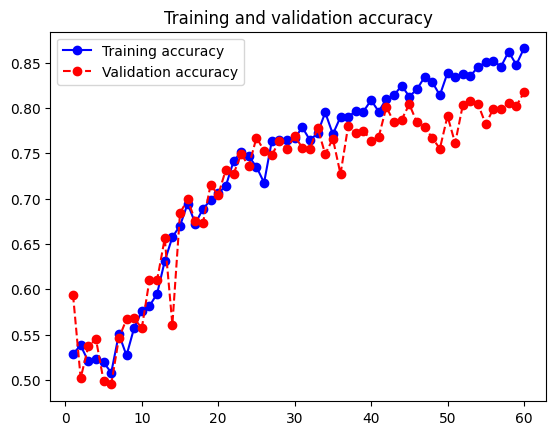

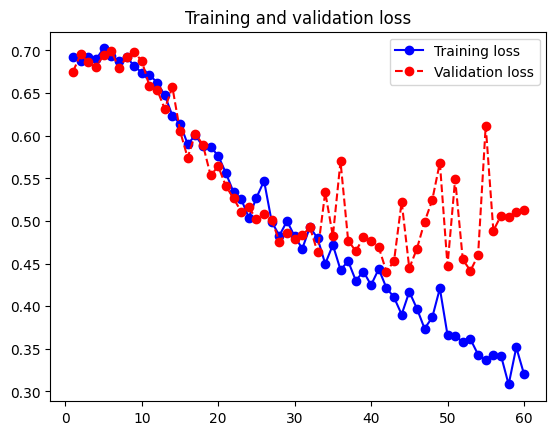

In [27]:
plot(history)

* Thanks to data augmentation and dropout, we start overfitting much later, around epochs 60–70 (compared to epoch 10 for the original model). 
* The validation accuracy ends up consistently in the 80–85% range—a big improvement over our first try.

In [28]:
test_model = keras.models.load_model(
    "models/U3-CNNs/dogs-vs-cats_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.7785 - loss: 0.4830
Test accuracy: 0.779
